In [3]:

# ═══════════════════════════════════════════════════════════════════════════════
# Train/Test notebook  —  load checkpoints from ./models and evaluate them on
# the saved test split in ./dataset/test.
#
# Steps:
#   1. Imports + paths
#   2. Define helpers + import model class from train.py
#   3. Single-threshold deep-dive  (CE / accuracy / per-position breakdown)
#   4. Multi-threshold sweep + plots
#
# Run data_generation.py and train.py first to populate ./dataset and ./models.
# ═══════════════════════════════════════════════════════════════════════════════

import os
import sys
import json
import importlib.util
from glob import glob

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ── paths (edit if your layout differs) ──────────────────────────────────────
HERE        = os.path.abspath('.')
DATA_DIR    = os.path.join(HERE, 'dataset')
MODELS_DIR  = os.path.join(HERE, 'models')
TRAIN_PY    = os.path.join(HERE, 'train.py')

DEVICE      = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE  = 256             # for eval
N_EVAL_SEQS = None            # None → use all test sequences

print(f"DATA_DIR   = {DATA_DIR}")
print(f"MODELS_DIR = {MODELS_DIR}")
print(f"device     = {DEVICE}")

# Import DisentangledTransformer + helpers directly from train.py so the model
# architecture stays in sync with the training script.
spec = importlib.util.spec_from_file_location('train_module', TRAIN_PY)
train_module = importlib.util.module_from_spec(spec); spec.loader.exec_module(train_module)
DisentangledTransformer = train_module.DisentangledTransformer

# Discover what thresholds have checkpoints + test data
def discovered_thresholds():
    ckpts = {float(os.path.basename(p)[len('model_x_'):-len('.pth')])
             for p in glob(os.path.join(MODELS_DIR, 'model_x_*.pth'))}
    tests = {float(os.path.basename(p)[len('data_x_'):-len('.pt')])
             for p in glob(os.path.join(DATA_DIR, 'test', 'data_x_*.pt'))}
    return sorted(ckpts & tests)

THRESHOLDS = discovered_thresholds()
print(f"thresholds available (ckpt ∩ test data): {THRESHOLDS}")


DATA_DIR   = /home/hariguru/ashutosh/ICL/4.training_for_oracle/dataset
MODELS_DIR = /home/hariguru/ashutosh/ICL/4.training_for_oracle/models
device     = cuda:1
thresholds available (ckpt ∩ test data): [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


In [4]:
# ═══════════════════════════════════════════════════════════════════════════════
# Optional: generate new train/test data from inside the notebook.
# Set GENERATE_DATA = True to (re)write dataset/train/data_x_*.pt and
# dataset/test/data_x_*.pt for every threshold in THRS_TO_GENERATE.
#
# Default GENERATE_DATA = False, so opening + running-all on a fresh notebook
# does NOT clobber existing data.  When True, behaves exactly like
# `python data_generation.py` with the same args.
# ═══════════════════════════════════════════════════════════════════════════════

# ── knobs ────────────────────────────────────────────────────────────────────
GENERATE_DATA       = False                                       # master toggle
THRS_TO_GENERATE    = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
GEN_TRAIN_SIZE      = 100_000
GEN_TEST_SIZE       = 5_000
GEN_SEQ_LEN         = 500
GEN_VOCAB_SET1      = 10
GEN_TOTAL_VOCAB     = 20
GEN_SEED            = 0                                           # base RNG seed
GEN_OVERWRITE       = False                                       # skip files that already exist
GEN_QUIET           = False
# ─────────────────────────────────────────────────────────────────────────────

# Pull the exact `generate_dataset` from data_generation.py so the two stay
# byte-identical and we never drift from the CLI script.
DATA_GEN_PY = os.path.join(HERE, 'data_generation.py')
_spec = importlib.util.spec_from_file_location('data_generation_module', DATA_GEN_PY)
_dg_module = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(_dg_module)
generate_dataset = _dg_module.generate_dataset                    # same function as the CLI

def regenerate_dataset(thresholds, train_size, test_size, seq_len,
                       vocab_set1, total_vocab, base_seed,
                       output_dir, overwrite=False, quiet=False):
    """Notebook-side driver that writes dataset/{train,test}/data_x_*.pt files
    identical in format to those produced by `python data_generation.py`."""
    train_dir = os.path.join(output_dir, 'train')
    test_dir  = os.path.join(output_dir, 'test')
    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir,  exist_ok=True)

    if not quiet:
        print(f"Generating data → {os.path.abspath(output_dir)}")
        print(f"  thresholds : {thresholds}")
        print(f"  train/test : {train_size} / {test_size} per threshold")
        print(f"  seq_len    : {seq_len}   vocab: V_sig={vocab_set1}, V={total_vocab}")
        print(f"  base seed  : {base_seed}   overwrite: {overwrite}\n")

    t0 = time.time()
    for i, thr in enumerate(thresholds):
        seed_thr = base_seed + i * 1000
        for split, n, sub in [('train', train_size, train_dir),
                              ('test',  test_size,  test_dir)]:
            out = os.path.join(sub, f'data_x_{thr}.pt')
            if (not overwrite) and os.path.exists(out):
                if not quiet:
                    print(f"  [skip] {out} (exists)")
                continue
            split_seed = seed_thr + (0 if split == 'train' else 1)
            rng = np.random.default_rng(split_seed)
            x, y, trans = generate_dataset(n, seq_len, thr,
                                           vocab_set1, total_vocab, rng)
            torch.save({
                'x': x, 'y': y, 'transitions': trans,
                'threshold':   float(thr),
                'seq_len':     seq_len,
                'vocab_set1':  vocab_set1,
                'total_vocab': total_vocab,
                'num_samples': n,
                'seed':        split_seed,
                'split':       split,
            }, out)
            if not quiet:
                print(f"  [ok]   {split:5s} thr={thr:.2f}  N={n:>6d} → {out}")
    if not quiet:
        print(f"\nDone in {time.time()-t0:.1f}s.")

# imports used above
import importlib.util, time

if GENERATE_DATA:
    regenerate_dataset(
        thresholds   = THRS_TO_GENERATE,
        train_size   = GEN_TRAIN_SIZE,
        test_size    = GEN_TEST_SIZE,
        seq_len      = GEN_SEQ_LEN,
        vocab_set1   = GEN_VOCAB_SET1,
        total_vocab  = GEN_TOTAL_VOCAB,
        base_seed    = GEN_SEED,
        output_dir   = DATA_DIR,
        overwrite    = GEN_OVERWRITE,
        quiet        = GEN_QUIET,
    )
    # refresh the discovered-thresholds list (cell 1 ran before any files existed)
    THRESHOLDS = discovered_thresholds()
    print(f"\nthresholds now available: {THRESHOLDS}")
else:
    print("GENERATE_DATA = False — skipping data generation.")
    print(f"thresholds already on disk: {THRESHOLDS}")


GENERATE_DATA = False — skipping data generation.
thresholds already on disk: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# Helpers — load a split + the matching checkpoint, run inference,
# return per-position CE / accuracy.
# Also defines PerfectInductionTransformer (W*, ultimate) used in cells below.
# ═══════════════════════════════════════════════════════════════════════════════
import torch.nn as nn

def load_split_blob(thr, split):
    """split in {'train', 'test'}"""
    path = os.path.join(DATA_DIR, split, f'data_x_{thr}.pt')
    return torch.load(path, weights_only=False)


def load_model_for_threshold(thr, attn_dim=None, bias=None):
    """Load DisentangledTransformer checkpoint.
    attn_dim / bias read from metrics JSON if available;
    fallback: attn_dim = total_vocab + seq_len (matches W* dimensionality)."""
    blob = load_split_blob(thr, 'test')
    V = int(blob['total_vocab']); T_seq = int(blob['seq_len'])
    auto_attn_dim = V + T_seq           # W*-equivalent dimension

    metrics_path = os.path.join(MODELS_DIR, f'metrics_x_{thr}.json')
    if os.path.exists(metrics_path):
        with open(metrics_path) as f:
            cfg = json.load(f).get('config', {})
        if attn_dim is None: attn_dim = cfg.get('attn_dim', auto_attn_dim)
        if bias     is None: bias     = cfg.get('bias',     True)
    else:
        if attn_dim is None: attn_dim = auto_attn_dim
        if bias     is None: bias     = True

    model = DisentangledTransformer(
        total_vocab=V, seq_len=T_seq, attn_dim=attn_dim, bias=bias,
    ).to(DEVICE)
    state = torch.load(os.path.join(MODELS_DIR, f'model_x_{thr}.pth'),
                       map_location=DEVICE, weights_only=False)
    model.load_state_dict(state)
    model.eval()
    return model, blob


@torch.no_grad()
def evaluate(model, x, y, batch_size=256, n_seqs=None):
    """Return per-position CE, accuracy, and signal/noise breakdown."""
    if n_seqs is not None:
        x = x[:n_seqs]; y = y[:n_seqs]
    T = x.shape[1]
    V = model.total_vocab

    ce_per_pos     = torch.zeros(T, dtype=torch.float64)
    cnt_per_pos    = torch.zeros(T, dtype=torch.float64)
    acc_per_pos    = torch.zeros(T, dtype=torch.float64)
    sig_mask_total = torch.zeros(T, dtype=torch.float64)
    sig_ce_total   = torch.zeros(T, dtype=torch.float64)
    nse_ce_total   = torch.zeros(T, dtype=torch.float64)

    V_sig = model.total_vocab // 2

    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i + batch_size].to(DEVICE, non_blocking=True)
        yb = y[i:i + batch_size].to(DEVICE, non_blocking=True)
        logits = model(xb)
        ce = F.cross_entropy(logits.reshape(-1, V), yb.reshape(-1),
                             reduction='none').reshape(yb.shape)
        pred = logits.argmax(-1)
        ok   = (pred == yb).float()

        ce_per_pos     += ce.sum(0).double().cpu()
        cnt_per_pos    += yb.shape[0]
        acc_per_pos    += ok.sum(0).double().cpu()
        is_sig          = (yb < V_sig).float()
        sig_ce_total   += (ce * is_sig).sum(0).double().cpu()
        nse_ce_total   += (ce * (1 - is_sig)).sum(0).double().cpu()
        sig_mask_total += is_sig.sum(0).double().cpu()

    ce_per_pos  /= cnt_per_pos
    acc_per_pos /= cnt_per_pos
    safe_sig = sig_ce_total / sig_mask_total.clamp(min=1)
    safe_nse = nse_ce_total / (cnt_per_pos - sig_mask_total).clamp(min=1)

    return {
        'ce_overall':        float(ce_per_pos.mean()),
        'acc_overall':       float(acc_per_pos.mean()),
        'ce_per_pos':        ce_per_pos.numpy(),
        'acc_per_pos':       acc_per_pos.numpy(),
        'ce_signal_per_pos': safe_sig.numpy(),
        'ce_noise_per_pos':  safe_nse.numpy(),
    }


# ── PerfectInductionTransformer (W*, ultimate) ──────────────────────────────────────
# Defined here so it is available in both the multi-threshold sweep (cell below)
# and the CE-breakdown cell.  attn_dim = total_vocab + seq_len, which is
# identical to the W* construction and matches the trained model when
# train.py is run with the default --attn_dim (auto).

class _ConcatAttn(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        s = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: s = s + mask
        return torch.cat([x, self.W_o(torch.bmm(F.softmax(s, dim=-1), V))], dim=-1)

class PerfectInductionTransformer(nn.Module):
    """Hand-constructed induction head (ultimate priority-override query).
    attn_dim = total_vocab + seq_len, identical to the W* construction."""
    def __init__(self, total_vocab, seq_len, vocab_set1):
        super().__init__()
        self.total_vocab = total_vocab
        self.seq_len     = seq_len
        self.vocab_set1  = vocab_set1
        self.initial_dim = total_vocab + seq_len
        self.attn_dim    = self.initial_dim       # W* sets attn_dim = V + T
        self.layer1 = _ConcatAttn(self.initial_dim,                 self.attn_dim)
        self.layer2 = _ConcatAttn(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, total_vocab, bias=False)
        self._set_weights()
    def _set_weights(self):
        V = self.total_vocab; T = self.seq_len; D = self.attn_dim; V_r = self.vocab_set1
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        T1 = torch.zeros(D, D)
        for k in range(V_r, V): T1[k, :] = -1e9
        alpha_pos = 20.0
        for tq in range(T):
            for tk in range(T):
                if tq == tk: T1[V + tk, V + tq] = -1e9
                else:        T1[V + tk, V + tq] = -alpha_pos * (tq - tk)
        self.layer1.W_k.weight.data = T1.t()
        Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
        self.layer1.W_v.weight.data = Wv1
        self.layer1.W_o.weight.data = torch.eye(D)
        in2 = D + D
        Wq2 = torch.zeros(D, in2)
        Wq2[:V_r, :V_r]    = torch.eye(V_r) * (D ** 0.5) * 1000.0
        Wq2[:V_r, D:D+V_r] = torch.eye(V_r) * (D ** 0.5) * 50.0
        for v in range(V): Wq2[V_r, v] = (D ** 0.5) * 10.0
        self.layer2.W_q.weight.data = Wq2
        Wk2 = torch.zeros(D, in2); Wk2[:V, D:D+V] = torch.eye(V)
        for v in range(V_r, V): Wk2[V_r, v] = -50000.0
        self.layer2.W_k.weight.data = Wk2
        Wv2 = torch.zeros(D, in2); Wv2[:V, :V] = torch.eye(V)
        self.layer2.W_v.weight.data = Wv2
        self.layer2.W_o.weight.data = torch.eye(D)
        Wfc = torch.zeros(V, in2 + D); Wfc[:V, in2:in2+V] = torch.eye(V)
        self.fc_out.weight.data = Wfc
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s = self.layer1(s, mask); s = self.layer2(s, mask)
        return self.fc_out(s)


threshold x = 0.1
  train  N=50000   acc=0.0924   CE=2.6029
  test   N=1000    acc=0.0896    CE=2.6048


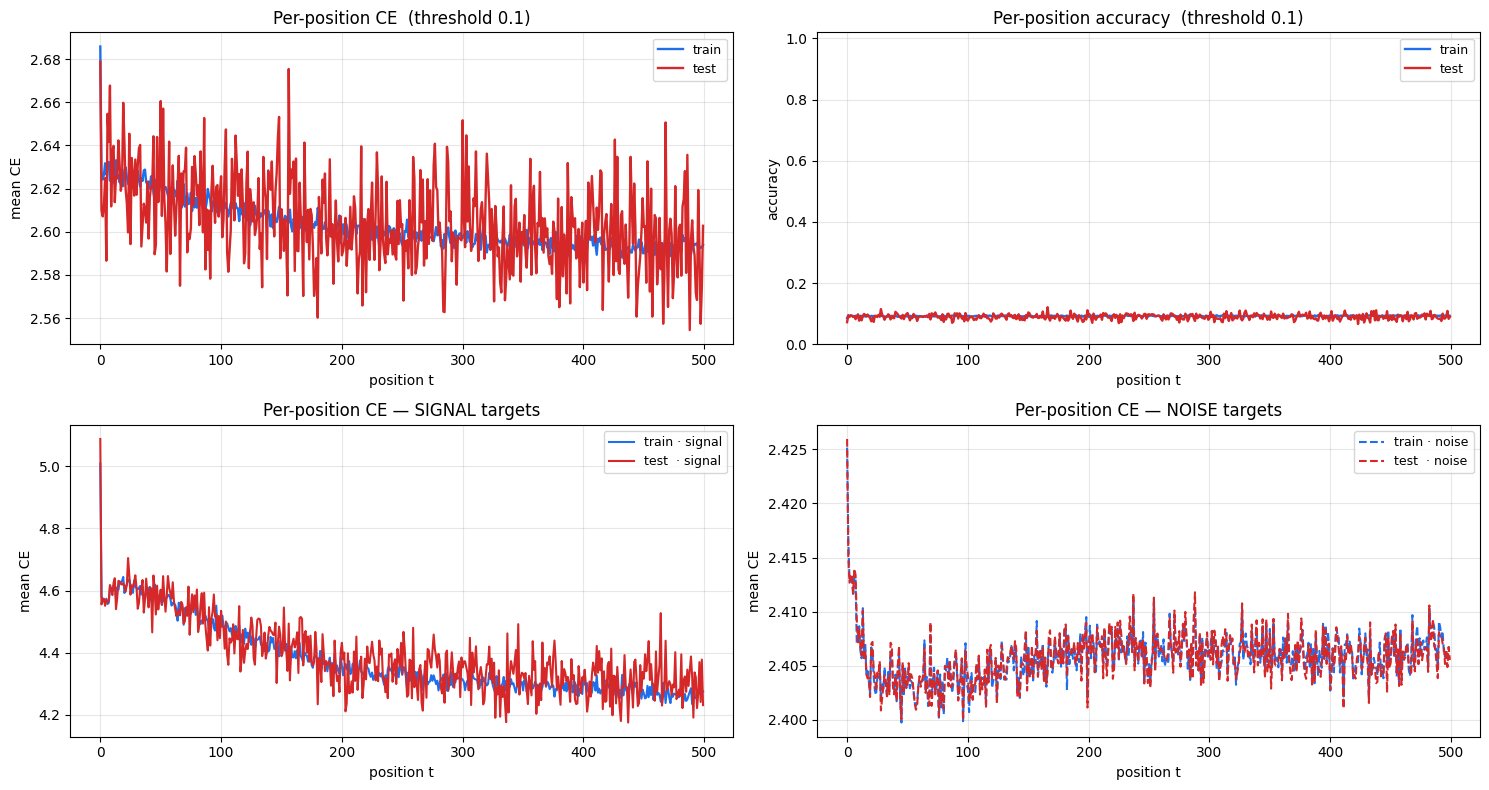

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# Single-threshold deep dive — load model, evaluate on BOTH train and test,
# overlay per-position CE / accuracy curves.
# ═══════════════════════════════════════════════════════════════════════════════

INSPECT_THR = THRESHOLDS[-1] if THRESHOLDS else 0.9   # change to inspect another

model, test_blob = load_model_for_threshold(INSPECT_THR)
train_blob       = load_split_blob(INSPECT_THR, 'train')

stats_train = evaluate(model, train_blob['x'], train_blob['y'],
                       batch_size=BATCH_SIZE, n_seqs=N_EVAL_SEQS)
stats_test  = evaluate(model, test_blob['x'],  test_blob['y'],
                       batch_size=BATCH_SIZE, n_seqs=N_EVAL_SEQS)

print(f"threshold x = {INSPECT_THR}")
print(f"  train  N={train_blob['x'].shape[0]}   acc={stats_train['acc_overall']:.4f}   "
      f"CE={stats_train['ce_overall']:.4f}")
print(f"  test   N={test_blob['x'].shape[0]}    acc={stats_test['acc_overall']:.4f}    "
      f"CE={stats_test['ce_overall']:.4f}")

T = stats_test['ce_per_pos'].shape[0]
positions = np.arange(T)
TRAIN_C, TEST_C = '#1f6feb', '#d62828'

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# ── Row 1: train vs test per-position CE / accuracy ─────────────────────────
ax = axes[0, 0]
ax.plot(positions, stats_train['ce_per_pos'], color=TRAIN_C, lw=1.7, label='train')
ax.plot(positions, stats_test ['ce_per_pos'], color=TEST_C,  lw=1.7, label='test')
ax.set_title(f'Per-position CE  (threshold {INSPECT_THR})')
ax.set_xlabel('position t'); ax.set_ylabel('mean CE')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[0, 1]
ax.plot(positions, stats_train['acc_per_pos'], color=TRAIN_C, lw=1.7, label='train')
ax.plot(positions, stats_test ['acc_per_pos'], color=TEST_C,  lw=1.7, label='test')
ax.set_title(f'Per-position accuracy  (threshold {INSPECT_THR})')
ax.set_xlabel('position t'); ax.set_ylabel('accuracy')
ax.set_ylim(0, 1.02); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ── Row 2: signal-target CE  vs  noise-target CE, train + test ──────────────
ax = axes[1, 0]
ax.plot(positions, stats_train['ce_signal_per_pos'], color=TRAIN_C, ls='-',  lw=1.5, label='train · signal')
ax.plot(positions, stats_test ['ce_signal_per_pos'], color=TEST_C,  ls='-',  lw=1.5, label='test  · signal')
ax.set_title('Per-position CE — SIGNAL targets')
ax.set_xlabel('position t'); ax.set_ylabel('mean CE')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1, 1]
ax.plot(positions, stats_train['ce_noise_per_pos'], color=TRAIN_C, ls='--', lw=1.5, label='train · noise')
ax.plot(positions, stats_test ['ce_noise_per_pos'], color=TEST_C,  ls='--', lw=1.5, label='test  · noise')
ax.set_title('Per-position CE — NOISE targets')
ax.set_xlabel('position t'); ax.set_ylabel('mean CE')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


  x=0.10  train acc=0.0924 CE=2.6029   |   test acc=0.0896 CE=2.6048   |   W* CE=3.0199   |   constr-α(α=x) CE=2.4697
  x=0.20  train acc=0.0901 CE=2.6674   |   test acc=0.0882 CE=2.6702   |   W* CE=2.9705   |   constr-α(α=x) CE=2.4838
  x=0.30  train acc=0.1258 CE=2.6808   |   test acc=0.1239 CE=2.6852   |   W* CE=2.9199   |   constr-α(α=x) CE=2.4331
  x=0.40  train acc=0.1754 CE=2.6661   |   test acc=0.1748 CE=2.6672   |   W* CE=2.8695   |   constr-α(α=x) CE=2.3336
  x=0.50  train acc=0.1951 CE=2.6509   |   test acc=0.1941 CE=2.6557   |   W* CE=2.8200   |   constr-α(α=x) CE=2.1937
  x=0.60  train acc=0.2387 CE=2.5367   |   test acc=0.2384 CE=2.5369   |   W* CE=2.7688   |   constr-α(α=x) CE=2.0098
  x=0.70  train acc=0.2893 CE=2.3329   |   test acc=0.2892 CE=2.3360   |   W* CE=2.7181   |   constr-α(α=x) CE=1.7848
  x=0.80  train acc=0.3524 CE=2.0467   |   test acc=0.3507 CE=2.0527   |   W* CE=2.6688   |   constr-α(α=x) CE=1.5151
  x=0.90  train acc=0.4198 CE=1.6621   |   test acc=0.42

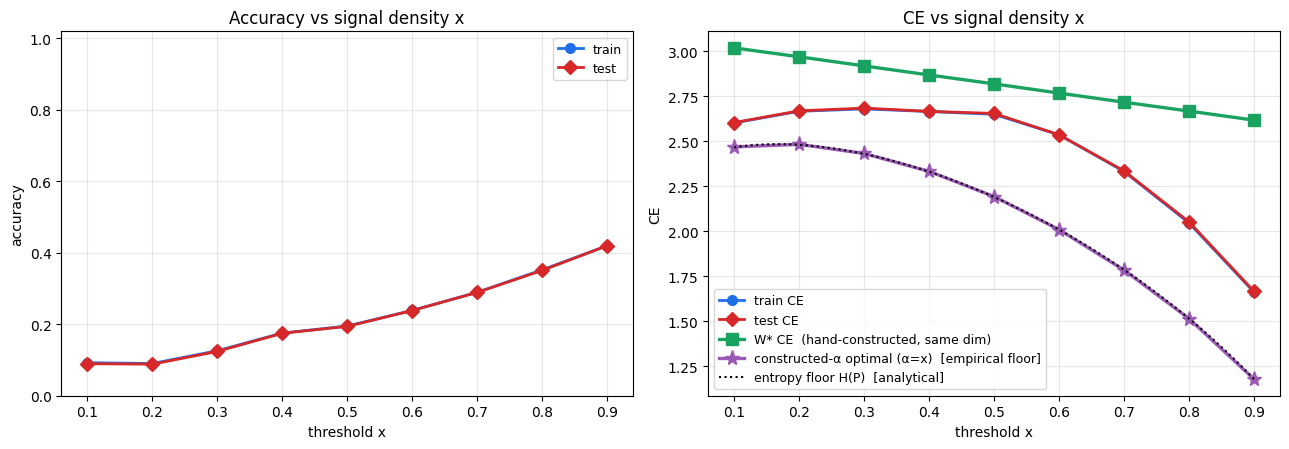


Saved eval summary -> /home/hariguru/ashutosh/ICL/4.training_for_oracle/models/eval_summary.json


In [7]:
# ═══════════════════════════════════════════════════════════════════════════════
# Multi-threshold sweep — evaluate every available checkpoint on BOTH train
# and test sets, plot overall CE + accuracy as a function of signal-density x.
# Curves shown on the CE plot:
#   • Trained model  — train CE + test CE
#   • W* (hand-constructed, same attn_dim = V+T)  — test CE
#   • Constructed-α optimal  (α = x, entropy floor, empirical)
#   • Analytical entropy floor  H(P)
# ═══════════════════════════════════════════════════════════════════════════════

def constructed_alpha_ce(blob, alpha):
    """Empirical mean CE of the constructed-α distribution on blob sequences."""
    x_np  = blob['x'].numpy()
    y_np  = blob['y'].numpy()
    trans = blob['transitions']
    V     = int(blob['total_vocab'])
    V_sig = int(blob['vocab_set1'])
    B, T  = x_np.shape

    is_ruled   = (x_np < V_sig)
    last_ruled = np.full((B, T), -1, dtype=np.int64)
    cur = np.full(B, -1, dtype=np.int64)
    for t in range(T):
        cur = np.where(is_ruled[:, t], x_np[:, t], cur)
        last_ruled[:, t] = cur

    trans_arr = np.empty((B, V_sig, 2), dtype=np.int64)
    for b in range(B):
        for r in range(V_sig):
            trans_arr[b, r] = trans[b][r]

    log_a    = np.log(max(alpha,   1e-12))
    log_oma  = np.log(max(1-alpha, 1e-12))
    log_Vsig = np.log(V_sig)
    log_2    = np.log(2.0)

    is_y_sig   = (y_np < V_sig)
    has_ruled  = (last_ruled >= 0)
    lr_safe    = np.clip(last_ruled, 0, V_sig - 1)
    valid      = trans_arr[np.arange(B)[:, None], lr_safe]
    is_valid_y = (y_np[..., None] == valid).any(axis=-1)

    ce_no_ruled        = np.where(is_y_sig, -(log_a - log_Vsig), -(log_oma - log_Vsig))
    ce_has_ruled_sig   = np.where(is_valid_y, -(log_a - log_2), 50.0)
    ce_has_ruled_noise = np.full((B, T), -(log_oma - log_Vsig))
    ce_has_ruled       = np.where(is_y_sig, ce_has_ruled_sig, ce_has_ruled_noise)
    ce                 = np.where(has_ruled, ce_has_ruled, ce_no_ruled)
    
    return float(ce.mean())


results = {}
for thr in THRESHOLDS:
    model, test_blob = load_model_for_threshold(thr)
    train_blob       = load_split_blob(thr, 'train')

    # trained model — train + test
    st_tr = evaluate(model, train_blob['x'], train_blob['y'],
                     batch_size=BATCH_SIZE, n_seqs=N_EVAL_SEQS)
    st_te = evaluate(model, test_blob['x'],  test_blob['y'],
                     batch_size=BATCH_SIZE, n_seqs=N_EVAL_SEQS)
    del model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

    # W* (hand-constructed, same dimensionality) — test only
    wstar = PerfectInductionTransformer(
        total_vocab=int(test_blob['total_vocab']),
        seq_len    =int(test_blob['seq_len']),
        vocab_set1 =int(test_blob['vocab_set1']),
    ).to(DEVICE).eval()
    st_ws = evaluate(wstar, test_blob['x'], test_blob['y'],
                     batch_size=BATCH_SIZE, n_seqs=N_EVAL_SEQS)
    del wstar
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

    # constructed-α optimal (alpha = x)
    cn_ce = constructed_alpha_ce(test_blob, alpha=float(thr))

    results[thr] = {
        'train_acc': st_tr['acc_overall'], 'train_ce': st_tr['ce_overall'],
        'test_acc':  st_te['acc_overall'], 'test_ce':  st_te['ce_overall'],
        'wstar_ce':  st_ws['ce_overall'],
        'cn_ce':     cn_ce,
    }
    print(f"  x={thr:.2f}  "
          f"train acc={st_tr['acc_overall']:.4f} CE={st_tr['ce_overall']:.4f}   |   "
          f"test acc={st_te['acc_overall']:.4f} CE={st_te['ce_overall']:.4f}   |   "
          f"W* CE={st_ws['ce_overall']:.4f}   |   "
          f"constr-α(α=x) CE={cn_ce:.4f}")

xs = list(results.keys())
TRAIN_C, TEST_C = '#1f6feb', '#d62828'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# accuracy
axes[0].plot(xs, [results[t]['train_acc'] for t in xs], 'o-',
             color=TRAIN_C, lw=2, ms=7, label='train')
axes[0].plot(xs, [results[t]['test_acc']  for t in xs], 'D-',
             color=TEST_C,  lw=2, ms=7, label='test')
axes[0].set_title('Accuracy vs signal density x')
axes[0].set_xlabel('threshold x'); axes[0].set_ylabel('accuracy')
axes[0].set_ylim(0, 1.02); axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=9)

# CE
def _entropy_floor(x):
    h = x * np.log(2) + (1 - x) * np.log(10)
    if 0 < x < 1:
        h += -(x * np.log(x) + (1 - x) * np.log(1 - x))
    return h
xs_fine = np.linspace(min(xs), max(xs), 200)
axes[1].plot(xs, [results[t]['train_ce'] for t in xs], 'o-',
             color=TRAIN_C, lw=2, ms=7, label='train CE')
axes[1].plot(xs, [results[t]['test_ce']  for t in xs], 'D-',
             color=TEST_C,  lw=2, ms=7, label='test CE')
axes[1].plot(xs, [results[t]['wstar_ce'] for t in xs], 's-',
             color='#1aa260', lw=2.4, ms=8,
             label='W* CE  (hand-constructed, same dim)')
axes[1].plot(xs, [results[t]['cn_ce']    for t in xs], '*-',
             color='#9b59b6', lw=2.4, ms=11,
             label='constructed-α optimal (α=x)  [empirical floor]')
axes[1].plot(xs_fine, [_entropy_floor(v) for v in xs_fine],
             ':', color='black', lw=1.5,
             label='entropy floor H(P)  [analytical]')
axes[1].set_title('CE vs signal density x')
axes[1].set_xlabel('threshold x'); axes[1].set_ylabel('CE')
axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

out_path = os.path.join(MODELS_DIR, 'eval_summary.json')
with open(out_path, 'w') as f:
    json.dump({str(t): results[t] for t in xs}, f, indent=2)
print(f"\nSaved eval summary -> {out_path}")


In [ ]:
# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-ε)·softmax(σ·logits)[k] + ε/(V-V_sig)  if k is noise
#                  = (1-ε)·softmax(σ·logits)[k]               if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─

# ── knobs ─
CE_BREAK_SIGMA   = 7
CE_BREAK_EPSILON = 0.0
CE_BREAK_LAST_N  = 500
CE_BREAK_ALPHA   = list(THRESHOLDS)

assert len(CE_BREAK_ALPHA) == len(THRESHOLDS)

# PerfectInductionTransformer and _ConcatAttn defined in helpers cell above.
def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):
    p = F.softmax(logits * sigma, dim=-1)
    boost = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = epsilon / (V - V_sig)
    p_hedged = (1.0 - epsilon) * p + boost
    p_target = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


def constructed_logq_at_targets(x_b, y_b, trans_list, alpha, V, V_sig):
    B, T = x_b.shape
    out = np.empty((B, T), dtype=np.float64)
    log_a, log_oma = np.log(max(alpha, 1e-12)), np.log(max(1 - alpha, 1e-12))
    log_Vsig, log_2 = np.log(V_sig), np.log(2.0)
    for b in range(B):
        x_seq, y_seq, trans = x_b[b], y_b[b], trans_list[b]
        last_ruled = -1
        for t in range(T):
            xt = int(x_seq[t])
            if xt < V_sig: last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                out[b, t] = -(log_a - log_Vsig) if y < V_sig else -(log_oma - log_Vsig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    out[b, t] = -(log_a - log_2) if y in (r1, r2) else 50.0
                else:
                    out[b, t] = -(log_oma - log_Vsig)
    return out


def run_ce_breakdown(split):
    results = {}
    for xi, thr in enumerate(THRESHOLDS):
        blob       = load_split_blob(thr, split)
        alpha      = float(CE_BREAK_ALPHA[xi])
        x_all, y_all = blob["x"], blob["y"]
        trans_all  = blob["transitions"]
        V          = int(blob["total_vocab"])
        V_sig      = int(blob["vocab_set1"])
        T_full     = int(blob["seq_len"])
        last_n     = min(CE_BREAK_LAST_N, T_full)
        pos_cutoff = T_full - last_n

        wstar      = PerfectInductionTransformer(V, T_full, V_sig).to(DEVICE).eval()
        trained, _ = load_model_for_threshold(thr)

        bk = {k: [] for k in [
            "ws_raw_sig","ws_raw_nse","ws_raw_all",
            "ws_hdg_sig","ws_hdg_nse","ws_hdg_all",
            "tr_raw_sig","tr_raw_nse","tr_raw_all",
            "tr_hdg_sig","tr_hdg_nse","tr_hdg_all",
            "cn_sig",    "cn_nse",    "cn_all",
        ]}

        N = x_all.shape[0]
        for i in range(0, N, BATCH_SIZE):
            bx = x_all[i:i+BATCH_SIZE].to(DEVICE)
            by = y_all[i:i+BATCH_SIZE].to(DEVICE)
            B, T = by.shape
            flat_y   = by.reshape(-1)
            is_sig   = flat_y < V_sig
            is_nse   = ~is_sig
            pos_idx  = torch.arange(T, device=DEVICE).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = is_nse & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx).reshape(-1, V)
                ws_raw = F.cross_entropy(ws_logits, flat_y, reduction="none")
                ws_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)
                tr_logits = trained(bx).reshape(-1, V)
                tr_raw = F.cross_entropy(tr_logits, flat_y, reduction="none")
                tr_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

                for ce, sk, nk, ak in [
                    (ws_raw, "ws_raw_sig","ws_raw_nse","ws_raw_all"),
                    (ws_hdg, "ws_hdg_sig","ws_hdg_nse","ws_hdg_all"),
                    (tr_raw, "tr_raw_sig","tr_raw_nse","tr_raw_all"),
                    (tr_hdg, "tr_hdg_sig","tr_hdg_nse","tr_hdg_all"),
                ]:
                    if sig_mask.any(): bk[sk].append(ce[sig_mask].mean().item())
                    if nse_mask.any(): bk[nk].append(ce[nse_mask].mean().item())
                    if all_mask.any(): bk[ak].append(ce[all_mask].mean().item())

            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            sub_trans = trans_all[i:i+BATCH_SIZE]
            ce_cn = constructed_logq_at_targets(x_np, y_np, sub_trans, alpha, V, V_sig)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(DEVICE).float()
            if sig_mask.any(): bk["cn_sig"].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): bk["cn_nse"].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): bk["cn_all"].append(ce_cn_flat[all_mask].mean().item())

        def _m(v): return float(np.nanmean(v)) if v else float("nan")
        results[thr] = {k: _m(v) for k, v in bk.items()}
        results[thr]["alpha"] = alpha
        _ws = results[thr]["ws_hdg_all"]; _tr = results[thr]["tr_raw_all"]; _cn = results[thr]["cn_all"]
        print(f"  [{split}] x={thr:.2f}   WS hdg all={_ws:.3f}   Tr raw all={_tr:.3f}   Cn all={_cn:.3f}")

        del wstar, trained
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return results


print("=== TEST ===")
ce_test  = run_ce_breakdown("test")
print("\n=== TRAIN ===")
ce_train = run_ce_breakdown("train")


# ── plot 3 panels  (solid = test, dashed/orange = train) ─
CE_BREAK_SIGMA   = 7
CE_BREAK_EPSILON = 0.0
CE_BREAK_LAST_N  = 500
CE_BREAK_ALPHA   = list(THRESHOLDS)

assert len(CE_BREAK_ALPHA) == len(THRESHOLDS)

# PerfectInductionTransformer and _ConcatAttn defined in helpers cell above.
def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):
    p = F.softmax(logits * sigma, dim=-1)
    boost = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = epsilon / (V - V_sig)
    p_hedged = (1.0 - epsilon) * p + boost
    p_target = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


def constructed_logq_at_targets(x_b, y_b, trans_list, alpha, V, V_sig):
    B, T = x_b.shape
    out = np.empty((B, T), dtype=np.float64)
    log_a, log_oma = np.log(max(alpha, 1e-12)), np.log(max(1 - alpha, 1e-12))
    log_Vsig, log_2 = np.log(V_sig), np.log(2.0)
    for b in range(B):
        x_seq, y_seq, trans = x_b[b], y_b[b], trans_list[b]
        last_ruled = -1
        for t in range(T):
            xt = int(x_seq[t])
            if xt < V_sig: last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                out[b, t] = -(log_a - log_Vsig) if y < V_sig else -(log_oma - log_Vsig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    out[b, t] = -(log_a - log_2) if y in (r1, r2) else 50.0
                else:
                    out[b, t] = -(log_oma - log_Vsig)
    return out


def run_ce_breakdown(split):
    results = {}
    for xi, thr in enumerate(THRESHOLDS):
        blob       = load_split_blob(thr, split)
        alpha      = float(CE_BREAK_ALPHA[xi])
        x_all, y_all = blob["x"], blob["y"]
        trans_all  = blob["transitions"]
        V          = int(blob["total_vocab"])
        V_sig      = int(blob["vocab_set1"])
        T_full     = int(blob["seq_len"])
        last_n     = min(CE_BREAK_LAST_N, T_full)
        pos_cutoff = T_full - last_n

        wstar      = PerfectInductionTransformer(V, T_full, V_sig).to(DEVICE).eval()
        trained, _ = load_model_for_threshold(thr)

        bk = {k: [] for k in [
            "ws_raw_sig","ws_raw_nse","ws_raw_all",
            "ws_hdg_sig","ws_hdg_nse","ws_hdg_all",
            "tr_raw_sig","tr_raw_nse","tr_raw_all",
            "tr_hdg_sig","tr_hdg_nse","tr_hdg_all",
            "cn_sig",    "cn_nse",    "cn_all",
        ]}

        N = x_all.shape[0]
        for i in range(0, N, BATCH_SIZE):
            bx = x_all[i:i+BATCH_SIZE].to(DEVICE)
            by = y_all[i:i+BATCH_SIZE].to(DEVICE)
            B, T = by.shape
            flat_y   = by.reshape(-1)
            is_sig   = flat_y < V_sig
            is_nse   = ~is_sig
            pos_idx  = torch.arange(T, device=DEVICE).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = is_nse & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx).reshape(-1, V)
                ws_raw = F.cross_entropy(ws_logits, flat_y, reduction="none")
                ws_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)
                tr_logits = trained(bx).reshape(-1, V)
                tr_raw = F.cross_entropy(tr_logits, flat_y, reduction="none")
                tr_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

                for ce, sk, nk, ak in [
                    (ws_raw, "ws_raw_sig","ws_raw_nse","ws_raw_all"),
                    (ws_hdg, "ws_hdg_sig","ws_hdg_nse","ws_hdg_all"),
                    (tr_raw, "tr_raw_sig","tr_raw_nse","tr_raw_all"),
                    (tr_hdg, "tr_hdg_sig","tr_hdg_nse","tr_hdg_all"),
                ]:
                    if sig_mask.any(): bk[sk].append(ce[sig_mask].mean().item())
                    if nse_mask.any(): bk[nk].append(ce[nse_mask].mean().item())
                    if all_mask.any(): bk[ak].append(ce[all_mask].mean().item())

            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            sub_trans = trans_all[i:i+BATCH_SIZE]
            ce_cn = constructed_logq_at_targets(x_np, y_np, sub_trans, alpha, V, V_sig)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(DEVICE).float()
            if sig_mask.any(): bk["cn_sig"].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): bk["cn_nse"].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): bk["cn_all"].append(ce_cn_flat[all_mask].mean().item())

        def _m(v): return float(np.nanmean(v)) if v else float("nan")
        results[thr] = {k: _m(v) for k, v in bk.items()}
        results[thr]["alpha"] = alpha
        _ws = results[thr]["ws_hdg_all"]; _tr = results[thr]["tr_raw_all"]; _cn = results[thr]["cn_all"]
        print(f"  [{split}] x={thr:.2f}   WS hdg all={_ws:.3f}   Tr raw all={_tr:.3f}   Cn all={_cn:.3f}")

        del wstar, trained
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return results


print("=== TEST ===")
ce_test  = run_ce_breakdown("test")
print("\n=== TRAIN ===")
ce_train = run_ce_breakdown("train")


# ── plot 3 panels  (solid = test, dashed/orange = train) ─
CE_BREAK_SIGMA   = 7
CE_BREAK_EPSILON = 0.0
CE_BREAK_LAST_N  = 500
CE_BREAK_ALPHA   = list(THRESHOLDS)

assert len(CE_BREAK_ALPHA) == len(THRESHOLDS)

# PerfectInductionTransformer and _ConcatAttn defined in helpers cell above.
def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):
    p = F.softmax(logits * sigma, dim=-1)
    boost = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = epsilon / (V - V_sig)
    p_hedged = (1.0 - epsilon) * p + boost
    p_target = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


def constructed_logq_at_targets(x_b, y_b, trans_list, alpha, V, V_sig):
    B, T = x_b.shape
    out = np.empty((B, T), dtype=np.float64)
    log_a, log_oma = np.log(max(alpha, 1e-12)), np.log(max(1 - alpha, 1e-12))
    log_Vsig, log_2 = np.log(V_sig), np.log(2.0)
    for b in range(B):
        x_seq, y_seq, trans = x_b[b], y_b[b], trans_list[b]
        last_ruled = -1
        for t in range(T):
            xt = int(x_seq[t])
            if xt < V_sig: last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                out[b, t] = -(log_a - log_Vsig) if y < V_sig else -(log_oma - log_Vsig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    out[b, t] = -(log_a - log_2) if y in (r1, r2) else 50.0
                else:
                    out[b, t] = -(log_oma - log_Vsig)
    return out


def run_ce_breakdown(split):
    results = {}
    for xi, thr in enumerate(THRESHOLDS):
        blob       = load_split_blob(thr, split)
        alpha      = float(CE_BREAK_ALPHA[xi])
        x_all, y_all = blob["x"], blob["y"]
        trans_all  = blob["transitions"]
        V          = int(blob["total_vocab"])
        V_sig      = int(blob["vocab_set1"])
        T_full     = int(blob["seq_len"])
        last_n     = min(CE_BREAK_LAST_N, T_full)
        pos_cutoff = T_full - last_n

        wstar      = PerfectInductionTransformer(V, T_full, V_sig).to(DEVICE).eval()
        trained, _ = load_model_for_threshold(thr)

        bk = {k: [] for k in [
            "ws_raw_sig","ws_raw_nse","ws_raw_all",
            "ws_hdg_sig","ws_hdg_nse","ws_hdg_all",
            "tr_raw_sig","tr_raw_nse","tr_raw_all",
            "tr_hdg_sig","tr_hdg_nse","tr_hdg_all",
            "cn_sig",    "cn_nse",    "cn_all",
        ]}

        N = x_all.shape[0]
        for i in range(0, N, BATCH_SIZE):
            bx = x_all[i:i+BATCH_SIZE].to(DEVICE)
            by = y_all[i:i+BATCH_SIZE].to(DEVICE)
            B, T = by.shape
            flat_y   = by.reshape(-1)
            is_sig   = flat_y < V_sig
            is_nse   = ~is_sig
            pos_idx  = torch.arange(T, device=DEVICE).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = is_nse & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx).reshape(-1, V)
                ws_raw = F.cross_entropy(ws_logits, flat_y, reduction="none")
                ws_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)
                tr_logits = trained(bx).reshape(-1, V)
                tr_raw = F.cross_entropy(tr_logits, flat_y, reduction="none")
                tr_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

                for ce, sk, nk, ak in [
                    (ws_raw, "ws_raw_sig","ws_raw_nse","ws_raw_all"),
                    (ws_hdg, "ws_hdg_sig","ws_hdg_nse","ws_hdg_all"),
                    (tr_raw, "tr_raw_sig","tr_raw_nse","tr_raw_all"),
                    (tr_hdg, "tr_hdg_sig","tr_hdg_nse","tr_hdg_all"),
                ]:
                    if sig_mask.any(): bk[sk].append(ce[sig_mask].mean().item())
                    if nse_mask.any(): bk[nk].append(ce[nse_mask].mean().item())
                    if all_mask.any(): bk[ak].append(ce[all_mask].mean().item())

            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            sub_trans = trans_all[i:i+BATCH_SIZE]
            ce_cn = constructed_logq_at_targets(x_np, y_np, sub_trans, alpha, V, V_sig)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(DEVICE).float()
            if sig_mask.any(): bk["cn_sig"].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): bk["cn_nse"].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): bk["cn_all"].append(ce_cn_flat[all_mask].mean().item())

        def _m(v): return float(np.nanmean(v)) if v else float("nan")
        results[thr] = {k: _m(v) for k, v in bk.items()}
        results[thr]["alpha"] = alpha
        _ws = results[thr]["ws_hdg_all"]; _tr = results[thr]["tr_raw_all"]; _cn = results[thr]["cn_all"]
        print(f"  [{split}] x={thr:.2f}   WS hdg all={_ws:.3f}   Tr raw all={_tr:.3f}   Cn all={_cn:.3f}")

        del wstar, trained
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return results


print("=== TEST ===")
ce_test  = run_ce_breakdown("test")
print("\n=== TRAIN ===")
ce_train = run_ce_breakdown("train")


# ── plot 3 panels  (solid = test, dashed/orange = train) ─
CE_BREAK_SIGMA   = 7
CE_BREAK_EPSILON = 0.0
CE_BREAK_LAST_N  = 500
CE_BREAK_ALPHA   = list(THRESHOLDS)

assert len(CE_BREAK_ALPHA) == len(THRESHOLDS)

# PerfectInductionTransformer and _ConcatAttn defined in helpers cell above.
def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):
    p = F.softmax(logits * sigma, dim=-1)
    boost = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = epsilon / (V - V_sig)
    p_hedged = (1.0 - epsilon) * p + boost
    p_target = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


def constructed_logq_at_targets(x_b, y_b, trans_list, alpha, V, V_sig):
    B, T = x_b.shape
    out = np.empty((B, T), dtype=np.float64)
    log_a, log_oma = np.log(max(alpha, 1e-12)), np.log(max(1 - alpha, 1e-12))
    log_Vsig, log_2 = np.log(V_sig), np.log(2.0)
    for b in range(B):
        x_seq, y_seq, trans = x_b[b], y_b[b], trans_list[b]
        last_ruled = -1
        for t in range(T):
            xt = int(x_seq[t])
            if xt < V_sig: last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                out[b, t] = -(log_a - log_Vsig) if y < V_sig else -(log_oma - log_Vsig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    out[b, t] = -(log_a - log_2) if y in (r1, r2) else 50.0
                else:
                    out[b, t] = -(log_oma - log_Vsig)
    return out


def run_ce_breakdown(split):
    results = {}
    for xi, thr in enumerate(THRESHOLDS):
        blob       = load_split_blob(thr, split)
        alpha      = float(CE_BREAK_ALPHA[xi])
        x_all, y_all = blob["x"], blob["y"]
        trans_all  = blob["transitions"]
        V          = int(blob["total_vocab"])
        V_sig      = int(blob["vocab_set1"])
        T_full     = int(blob["seq_len"])
        last_n     = min(CE_BREAK_LAST_N, T_full)
        pos_cutoff = T_full - last_n

        wstar      = PerfectInductionTransformer(V, T_full, V_sig).to(DEVICE).eval()
        trained, _ = load_model_for_threshold(thr)

        bk = {k: [] for k in [
            "ws_raw_sig","ws_raw_nse","ws_raw_all",
            "ws_hdg_sig","ws_hdg_nse","ws_hdg_all",
            "tr_raw_sig","tr_raw_nse","tr_raw_all",
            "tr_hdg_sig","tr_hdg_nse","tr_hdg_all",
            "cn_sig",    "cn_nse",    "cn_all",
        ]}

        N = x_all.shape[0]
        for i in range(0, N, BATCH_SIZE):
            bx = x_all[i:i+BATCH_SIZE].to(DEVICE)
            by = y_all[i:i+BATCH_SIZE].to(DEVICE)
            B, T = by.shape
            flat_y   = by.reshape(-1)
            is_sig   = flat_y < V_sig
            is_nse   = ~is_sig
            pos_idx  = torch.arange(T, device=DEVICE).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = is_nse & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx).reshape(-1, V)
                ws_raw = F.cross_entropy(ws_logits, flat_y, reduction="none")
                ws_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)
                tr_logits = trained(bx).reshape(-1, V)
                tr_raw = F.cross_entropy(tr_logits, flat_y, reduction="none")
                tr_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

                for ce, sk, nk, ak in [
                    (ws_raw, "ws_raw_sig","ws_raw_nse","ws_raw_all"),
                    (ws_hdg, "ws_hdg_sig","ws_hdg_nse","ws_hdg_all"),
                    (tr_raw, "tr_raw_sig","tr_raw_nse","tr_raw_all"),
                    (tr_hdg, "tr_hdg_sig","tr_hdg_nse","tr_hdg_all"),
                ]:
                    if sig_mask.any(): bk[sk].append(ce[sig_mask].mean().item())
                    if nse_mask.any(): bk[nk].append(ce[nse_mask].mean().item())
                    if all_mask.any(): bk[ak].append(ce[all_mask].mean().item())

            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            sub_trans = trans_all[i:i+BATCH_SIZE]
            ce_cn = constructed_logq_at_targets(x_np, y_np, sub_trans, alpha, V, V_sig)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(DEVICE).float()
            if sig_mask.any(): bk["cn_sig"].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): bk["cn_nse"].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): bk["cn_all"].append(ce_cn_flat[all_mask].mean().item())

        def _m(v): return float(np.nanmean(v)) if v else float("nan")
        results[thr] = {k: _m(v) for k, v in bk.items()}
        results[thr]["alpha"] = alpha
        _ws = results[thr]["ws_hdg_all"]; _tr = results[thr]["tr_raw_all"]; _cn = results[thr]["cn_all"]
        print(f"  [{split}] x={thr:.2f}   WS hdg all={_ws:.3f}   Tr raw all={_tr:.3f}   Cn all={_cn:.3f}")

        del wstar, trained
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return results


print("=== TEST ===")
ce_test  = run_ce_breakdown("test")
print("\n=== TRAIN ===")
ce_train = run_ce_breakdown("train")


# ── plot 3 panels  (solid = test, dashed/orange = train) ─
CE_BREAK_SIGMA   = 7
CE_BREAK_EPSILON = 0.0
CE_BREAK_LAST_N  = 500
CE_BREAK_ALPHA   = list(THRESHOLDS)

assert len(CE_BREAK_ALPHA) == len(THRESHOLDS)

# PerfectInductionTransformer and _ConcatAttn defined in helpers cell above.
def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):
    p = F.softmax(logits * sigma, dim=-1)
    boost = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = epsilon / (V - V_sig)
    p_hedged = (1.0 - epsilon) * p + boost
    p_target = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


def constructed_logq_at_targets(x_b, y_b, trans_list, alpha, V, V_sig):
    B, T = x_b.shape
    out = np.empty((B, T), dtype=np.float64)
    log_a, log_oma = np.log(max(alpha, 1e-12)), np.log(max(1 - alpha, 1e-12))
    log_Vsig, log_2 = np.log(V_sig), np.log(2.0)
    for b in range(B):
        x_seq, y_seq, trans = x_b[b], y_b[b], trans_list[b]
        last_ruled = -1
        for t in range(T):
            xt = int(x_seq[t])
            if xt < V_sig: last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                out[b, t] = -(log_a - log_Vsig) if y < V_sig else -(log_oma - log_Vsig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    out[b, t] = -(log_a - log_2) if y in (r1, r2) else 50.0
                else:
                    out[b, t] = -(log_oma - log_Vsig)
    return out


def run_ce_breakdown(split):
    results = {}
    for xi, thr in enumerate(THRESHOLDS):
        blob       = load_split_blob(thr, split)
        alpha      = float(CE_BREAK_ALPHA[xi])
        x_all, y_all = blob["x"], blob["y"]
        trans_all  = blob["transitions"]
        V          = int(blob["total_vocab"])
        V_sig      = int(blob["vocab_set1"])
        T_full     = int(blob["seq_len"])
        last_n     = min(CE_BREAK_LAST_N, T_full)
        pos_cutoff = T_full - last_n

        wstar      = PerfectInductionTransformer(V, T_full, V_sig).to(DEVICE).eval()
        trained, _ = load_model_for_threshold(thr)

        bk = {k: [] for k in [
            "ws_raw_sig","ws_raw_nse","ws_raw_all",
            "ws_hdg_sig","ws_hdg_nse","ws_hdg_all",
            "tr_raw_sig","tr_raw_nse","tr_raw_all",
            "tr_hdg_sig","tr_hdg_nse","tr_hdg_all",
            "cn_sig",    "cn_nse",    "cn_all",
        ]}

        N = x_all.shape[0]
        for i in range(0, N, BATCH_SIZE):
            bx = x_all[i:i+BATCH_SIZE].to(DEVICE)
            by = y_all[i:i+BATCH_SIZE].to(DEVICE)
            B, T = by.shape
            flat_y   = by.reshape(-1)
            is_sig   = flat_y < V_sig
            is_nse   = ~is_sig
            pos_idx  = torch.arange(T, device=DEVICE).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = is_nse & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx).reshape(-1, V)
                ws_raw = F.cross_entropy(ws_logits, flat_y, reduction="none")
                ws_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)
                tr_logits = trained(bx).reshape(-1, V)
                tr_raw = F.cross_entropy(tr_logits, flat_y, reduction="none")
                tr_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

                for ce, sk, nk, ak in [
                    (ws_raw, "ws_raw_sig","ws_raw_nse","ws_raw_all"),
                    (ws_hdg, "ws_hdg_sig","ws_hdg_nse","ws_hdg_all"),
                    (tr_raw, "tr_raw_sig","tr_raw_nse","tr_raw_all"),
                    (tr_hdg, "tr_hdg_sig","tr_hdg_nse","tr_hdg_all"),
                ]:
                    if sig_mask.any(): bk[sk].append(ce[sig_mask].mean().item())
                    if nse_mask.any(): bk[nk].append(ce[nse_mask].mean().item())
                    if all_mask.any(): bk[ak].append(ce[all_mask].mean().item())

            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            sub_trans = trans_all[i:i+BATCH_SIZE]
            ce_cn = constructed_logq_at_targets(x_np, y_np, sub_trans, alpha, V, V_sig)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(DEVICE).float()
            if sig_mask.any(): bk["cn_sig"].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): bk["cn_nse"].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): bk["cn_all"].append(ce_cn_flat[all_mask].mean().item())

        def _m(v): return float(np.nanmean(v)) if v else float("nan")
        results[thr] = {k: _m(v) for k, v in bk.items()}
        results[thr]["alpha"] = alpha
        _ws = results[thr]["ws_hdg_all"]; _tr = results[thr]["tr_raw_all"]; _cn = results[thr]["cn_all"]
        print(f"  [{split}] x={thr:.2f}   WS hdg all={_ws:.3f}   Tr raw all={_tr:.3f}   Cn all={_cn:.3f}")

        del wstar, trained
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return results


print("=== TEST ===")
ce_test  = run_ce_breakdown("test")
print("\n=== TRAIN ===")
ce_train = run_ce_breakdown("train")


# ── plot 3 panels  (solid = test, dashed/orange = train) ─
xs = sorted(ce_test.keys())
def _g(res, k): return [res[x][k] for x in xs]
V_total = int(load_split_blob(xs[0], "test")["total_vocab"])
V_sig0  = int(load_split_blob(xs[0], "test")["vocab_set1"])

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
fig.suptitle(
    f"CE Breakdown — Signal vs Noise vs Combined  "
    f"(W* σ={CE_BREAK_SIGMA}, ε={CE_BREAK_EPSILON}, last {CE_BREAK_LAST_N} pos, α=x)  "
    f"[solid=test  |  dashed=train]",
    fontsize=13, fontweight="bold")

panels = [
    ("Signal positions  (next token in 0..V_sig-1)",
     "ws_raw_sig","ws_hdg_sig","tr_raw_sig","tr_hdg_sig","cn_sig",
     [(np.log(2), "gray", f"log(2)={np.log(2):.3f}  [50% floor]")]),
    ("Noise positions  (next token in V_sig..V-1)",
     "ws_raw_nse","ws_hdg_nse","tr_raw_nse","tr_hdg_nse","cn_nse",
     [(np.log(V_sig0),  "steelblue", f"log({V_sig0})={np.log(V_sig0):.3f}"),
      (np.log(V_total), "orange",    f"log({V_total})={np.log(V_total):.3f}  [uniform]")]),
    ("Combined  (signal + noise)",
     "ws_raw_all","ws_hdg_all","tr_raw_all","tr_hdg_all","cn_all", []),
]

for ax, (title, k_wsr, k_wsh, k_trr, k_trh, k_cn, hlines) in zip(axes, panels):
    ax.plot(xs, _g(ce_test,  k_wsr), "g--o", lw=1.6, ms=5, alpha=0.5, label="W* raw (test)")
    ax.plot(xs, _g(ce_test,  k_wsh), "g-o",  lw=2.4, ms=7,            label=f"W* hedged (test, σ={CE_BREAK_SIGMA})")
    ax.plot(xs, _g(ce_test,  k_trr), "r--D", lw=1.6, ms=5, alpha=0.5, label="Trained raw (test)")
    ax.plot(xs, _g(ce_test,  k_trh), "r-D",  lw=2.4, ms=7,            label="Trained hedged (test)")
    ax.plot(xs, _g(ce_train, k_trr), color="#f4a261", ls="--", marker="D", lw=1.6, ms=5, alpha=0.7, label="Trained raw (train)")
    ax.plot(xs, _g(ce_train, k_trh), color="#e07a18", ls="-",  marker="D", lw=2.0, ms=6,            label="Trained hedged (train)")
    ax.plot(xs, _g(ce_test,  k_cn),  "b-*",  lw=2.6, ms=10, label="Constructed-α optimal")
    for yv, c, lab in hlines:
        ax.axhline(yv, color=c, ls=":", lw=1.3, label=lab)
    ax.set_title(f"{title}  |  last {CE_BREAK_LAST_N} pos", fontsize=11)
    ax.set_xlabel("signal density  x"); ax.set_ylabel("mean CE")
    ax.legend(fontsize=7.5, loc="best"); ax.grid(True, alpha=0.3); ax.set_ylim(bottom=0)

plt.tight_layout(); plt.show()


=== TEST ===
  [test] x=0.10   WS hdg all=4.915   Tr raw all=2.605   Cn all=2.470
  [test] x=0.20   WS hdg all=4.407   Tr raw all=2.670   Cn all=2.484
  [test] x=0.30   WS hdg all=3.940   Tr raw all=2.685   Cn all=2.433
  [test] x=0.40   WS hdg all=3.517   Tr raw all=2.667   Cn all=2.334
  [test] x=0.50   WS hdg all=3.120   Tr raw all=2.656   Cn all=2.194
  [test] x=0.60   WS hdg all=2.727   Tr raw all=2.537   Cn all=2.010
  [test] x=0.70   WS hdg all=2.349   Tr raw all=2.336   Cn all=1.785
  [test] x=0.80   WS hdg all=1.974   Tr raw all=2.053   Cn all=1.515
  [test] x=0.90   WS hdg all=1.604   Tr raw all=1.667   Cn all=1.179

=== TRAIN ===


  [train] x=0.10   WS hdg all=4.924   Tr raw all=2.603   Cn all=2.470
  [train] x=0.20   WS hdg all=4.398   Tr raw all=2.667   Cn all=2.484
  [train] x=0.30   WS hdg all=3.939   Tr raw all=2.681   Cn all=2.433


In [ ]:
# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═
# Ruled-token accuracy sweep  (train + test)
#   Evaluate accuracy ONLY on positions where the true next token is a
#   ruled token (y[t] < V_sig).  Compares:
#     • Trained model  (gradient-descent checkpoint)
#     • W* hand-constructed
#   Reference lines:
#     • 50% ceiling  — best any model can do (2 equally-likely transitions)
#     • Oracle step  — 0% at x<1/6,  50% at x≥1/6
# ═


@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─

@torch.no_grad()
def ruled_token_accuracy(model, x, y, V_sig, batch_size=256):
    model.eval()
    correct, total = 0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(DEVICE)
        yb = y[i:i+batch_size].to(DEVICE)
        pred = model(xb).argmax(-1)
        mask = yb < V_sig
        correct += (pred[mask] == yb[mask]).sum().item()
        total   += mask.sum().item()
    return correct / max(total, 1)


ruled_acc_results = {}
for thr in THRESHOLDS:
    test_blob  = load_split_blob(thr, "test")
    train_blob = load_split_blob(thr, "train")
    x_te, y_te = test_blob["x"],  test_blob["y"]
    x_tr, y_tr = train_blob["x"], train_blob["y"]
    V     = int(test_blob["total_vocab"])
    V_sig = int(test_blob["vocab_set1"])
    T_seq = int(test_blob["seq_len"])

    trained, _ = load_model_for_threshold(thr)
    wstar      = PerfectInductionTransformer(V, T_seq, V_sig).to(DEVICE).eval()

    tr_te_acc = ruled_token_accuracy(trained, x_te, y_te, V_sig)
    tr_tr_acc = ruled_token_accuracy(trained, x_tr, y_tr, V_sig)
    ws_te_acc = ruled_token_accuracy(wstar,   x_te, y_te, V_sig)
    ws_tr_acc = ruled_token_accuracy(wstar,   x_tr, y_tr, V_sig)

    ruled_acc_results[thr] = {
        "trained_test":  tr_te_acc, "trained_train": tr_tr_acc,
        "wstar_test":    ws_te_acc, "wstar_train":   ws_tr_acc,
    }
    print(f"  x={thr:.2f}   Trained: train={tr_tr_acc:.4f}  test={tr_te_acc:.4f}   "
          f"W*: train={ws_tr_acc:.4f}  test={ws_te_acc:.4f}")

    del trained, wstar
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


# ── plot ─
xs    = sorted(ruled_acc_results.keys())
tr_te = [ruled_acc_results[x]["trained_test"]  for x in xs]
tr_tr = [ruled_acc_results[x]["trained_train"] for x in xs]
ws_te = [ruled_acc_results[x]["wstar_test"]    for x in xs]
ws_tr = [ruled_acc_results[x]["wstar_train"]   for x in xs]

oracle_step = [0.0 if x < 1/6 else 0.5 for x in xs]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(xs, tr_te, "r-D",  lw=2.2, ms=8, label="Trained  (test)")
ax.plot(xs, tr_tr, color="#f4a261", ls="-", marker="D", lw=2.0, ms=7, label="Trained  (train)")
ax.plot(xs, ws_te, "g-o",  lw=2.2, ms=8, label="W* hand-constructed  (test)")
ax.plot(xs, ws_tr, color="#2dc653", ls="--", marker="o", lw=1.6, ms=6, alpha=0.7, label="W* hand-constructed  (train)")
ax.step(xs, oracle_step, where="post", color="black", lw=1.6, ls="--",
        label="Oracle ceiling: 0% at x<1/6,  50% at x>=1/6")
ax.axhline(0.5, color="gray", lw=1.2, ls=":",
           label="50% hard ceiling  (2 equally-likely transitions)")

ax.set_title("Accuracy on ruled-token positions only  (y[t] < V_sig)", fontsize=12)
ax.set_xlabel("Signal density  x  (threshold)", fontsize=11)
ax.set_ylabel("Accuracy on ruled tokens", fontsize=11)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


NameError: name 'THRESHOLDS' is not defined

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# CE BREAKDOWN  (train + test):  Signal positions  vs  Noise positions  vs  Combined
#   • W* (PerfectInductionTransformer)   raw + hedged
#   • Trained model from ./models/       raw + hedged
#   • Constructed-α optimal distribution (entropy floor)
#
#   Hedging is noise-tokens-only:
#       p_hedge[k] = (1-eps)*softmax(sigma*logits)[k] + eps/(V-V_sig)  if k is noise
#                  = (1-eps)*softmax(sigma*logits)[k]                   if k is ruled
#   solid lines = test   |   dashed/orange lines = train
# ═══════════════════════════════════════════════════════════════════════════════

# ── knobs ─────────────────────────────────────────────────────────────────────
CE_BREAK_SIGMA   = 7
CE_BREAK_EPSILON = 0.0
CE_BREAK_LAST_N  = 500
CE_BREAK_N_SEQS  = 2000      # cap sequences per threshold (None = use all)
CE_BREAK_ALPHA   = list(THRESHOLDS)

assert len(CE_BREAK_ALPHA) == len(THRESHOLDS)

# PerfectInductionTransformer and _ConcatAttn defined in helpers cell above.
def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):
    p = F.softmax(logits * sigma, dim=-1)
    boost = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = epsilon / (V - V_sig)
    p_hedged = (1.0 - epsilon) * p + boost
    p_target = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


def constructed_logq_at_targets(x_b, y_b, trans_list, alpha, V, V_sig):
    B, T = x_b.shape
    out = np.empty((B, T), dtype=np.float64)
    log_a, log_oma = np.log(max(alpha, 1e-12)), np.log(max(1 - alpha, 1e-12))
    log_Vsig, log_2 = np.log(V_sig), np.log(2.0)
    for b in range(B):
        x_seq, y_seq, trans = x_b[b], y_b[b], trans_list[b]
        last_ruled = -1
        for t in range(T):
            xt = int(x_seq[t])
            if xt < V_sig: last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                out[b, t] = -(log_a - log_Vsig) if y < V_sig else -(log_oma - log_Vsig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    out[b, t] = -(log_a - log_2) if y in (r1, r2) else 50.0
                else:
                    out[b, t] = -(log_oma - log_Vsig)
    return out


def run_ce_breakdown(split):
    results = {}
    for xi, thr in enumerate(THRESHOLDS):
        blob         = load_split_blob(thr, split)
        alpha        = float(CE_BREAK_ALPHA[xi])
        x_all, y_all = blob['x'], blob['y']
        trans_all    = blob['transitions']
        V            = int(blob['total_vocab'])
        V_sig        = int(blob['vocab_set1'])
        T_full       = int(blob['seq_len'])
        last_n       = min(CE_BREAK_LAST_N, T_full)
        pos_cutoff   = T_full - last_n

        # cap sequences for speed
        N = x_all.shape[0] if CE_BREAK_N_SEQS is None else min(CE_BREAK_N_SEQS, x_all.shape[0])
        x_all, y_all, trans_all = x_all[:N], y_all[:N], trans_all[:N]

        wstar      = PerfectInductionTransformer(V, T_full, V_sig).to(DEVICE).eval()
        trained, _ = load_model_for_threshold(thr)

        bk = {k: [] for k in [
            'ws_raw_sig', 'ws_raw_nse', 'ws_raw_all',
            'ws_hdg_sig', 'ws_hdg_nse', 'ws_hdg_all',
            'tr_raw_sig', 'tr_raw_nse', 'tr_raw_all',
            'tr_hdg_sig', 'tr_hdg_nse', 'tr_hdg_all',
            'cn_sig',     'cn_nse',     'cn_all',
        ]}

        for i in range(0, N, BATCH_SIZE):
            bx = x_all[i:i+BATCH_SIZE].to(DEVICE)
            by = y_all[i:i+BATCH_SIZE].to(DEVICE)
            B, T   = by.shape
            flat_y = by.reshape(-1)
            is_sig = flat_y < V_sig
            pos_idx  = torch.arange(T, device=DEVICE).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = ~is_sig & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx).reshape(-1, V)
                ws_raw = F.cross_entropy(ws_logits, flat_y, reduction='none')
                ws_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)
                tr_logits = trained(bx).reshape(-1, V)
                tr_raw = F.cross_entropy(tr_logits, flat_y, reduction='none')
                tr_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

            for ce, sk, nk, ak in [
                (ws_raw, 'ws_raw_sig', 'ws_raw_nse', 'ws_raw_all'),
                (ws_hdg, 'ws_hdg_sig', 'ws_hdg_nse', 'ws_hdg_all'),
                (tr_raw, 'tr_raw_sig', 'tr_raw_nse', 'tr_raw_all'),
                (tr_hdg, 'tr_hdg_sig', 'tr_hdg_nse', 'tr_hdg_all'),
            ]:
                if sig_mask.any(): bk[sk].append(ce[sig_mask].mean().item())
                if nse_mask.any(): bk[nk].append(ce[nse_mask].mean().item())
                if all_mask.any(): bk[ak].append(ce[all_mask].mean().item())

            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            ce_cn = constructed_logq_at_targets(x_np, y_np, trans_all[i:i+BATCH_SIZE], alpha, V, V_sig)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(DEVICE).float()
            if sig_mask.any(): bk['cn_sig'].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): bk['cn_nse'].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): bk['cn_all'].append(ce_cn_flat[all_mask].mean().item())

        def _m(v): return float(np.nanmean(v)) if v else float('nan')
        results[thr] = {k: _m(v) for k, v in bk.items()}
        results[thr]['alpha'] = alpha
        ws_all = results[thr]['ws_hdg_all']
        tr_all = results[thr]['tr_raw_all']
        cn_all = results[thr]['cn_all']
        print(f'  [{split}] x={thr:.2f}  N={N}  WS hdg all={ws_all:.3f}  Tr raw all={tr_all:.3f}  Cn all={cn_all:.3f}')

        del wstar, trained
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return results


print('=== TEST ===')
ce_test  = run_ce_breakdown('test')
print('\n=== TRAIN ===')
ce_train = run_ce_breakdown('train')


# ── plot 3 panels  (solid = test, dashed/orange = train) ──────────────────────
xs = sorted(ce_test.keys())
def _g(res, k): return [res[x][k] for x in xs]
V_total = int(load_split_blob(xs[0], 'test')['total_vocab'])
V_sig0  = int(load_split_blob(xs[0], 'test')['vocab_set1'])

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
fig.suptitle(
    f'CE Breakdown — Signal vs Noise vs Combined  '
    f'(W* sig={CE_BREAK_SIGMA}, eps={CE_BREAK_EPSILON}, last {CE_BREAK_LAST_N} pos, N={CE_BREAK_N_SEQS}, alpha=x)  '
    f'[solid=test  |  dashed=train]',
    fontsize=13, fontweight='bold')

panels = [
    ('Signal positions  (next token in 0..V_sig-1)',
     'ws_raw_sig', 'ws_hdg_sig', 'tr_raw_sig', 'tr_hdg_sig', 'cn_sig',
     [(np.log(2), 'gray', f'log(2)={np.log(2):.3f}  [50% floor]')]),
    ('Noise positions  (next token in V_sig..V-1)',
     'ws_raw_nse', 'ws_hdg_nse', 'tr_raw_nse', 'tr_hdg_nse', 'cn_nse',
     [(np.log(V_sig0),  'steelblue', f'log({V_sig0})={np.log(V_sig0):.3f}'),
      (np.log(V_total), 'orange',    f'log({V_total})={np.log(V_total):.3f}  [uniform]')]),
    ('Combined  (signal + noise)',
     'ws_raw_all', 'ws_hdg_all', 'tr_raw_all', 'tr_hdg_all', 'cn_all', []),
]

for ax, (title, k_wsr, k_wsh, k_trr, k_trh, k_cn, hlines) in zip(axes, panels):
    ax.plot(xs, _g(ce_test,  k_wsr), 'g--o', lw=1.6, ms=5, alpha=0.5, label='W* raw (test)')
    ax.plot(xs, _g(ce_test,  k_wsh), 'g-o',  lw=2.4, ms=7,            label=f'W* hedged (test, sig={CE_BREAK_SIGMA})')
    ax.plot(xs, _g(ce_test,  k_trr), 'r--D', lw=1.6, ms=5, alpha=0.5, label='Trained raw (test)')
    ax.plot(xs, _g(ce_test,  k_trh), 'r-D',  lw=2.4, ms=7,            label='Trained hedged (test)')
    ax.plot(xs, _g(ce_train, k_trr), color='#f4a261', ls='--', marker='D', lw=1.6, ms=5, alpha=0.7, label='Trained raw (train)')
    ax.plot(xs, _g(ce_train, k_trh), color='#e07a18', ls='-',  marker='D', lw=2.0, ms=6,            label='Trained hedged (train)')
    ax.plot(xs, _g(ce_test,  k_cn),  'b-*',  lw=2.6, ms=10, label='Constructed-alpha optimal')
    for yv, c, lab in hlines:
        ax.axhline(yv, color=c, ls=':', lw=1.3, label=lab)
    ax.set_title(f'{title}  |  last {CE_BREAK_LAST_N} pos', fontsize=11)
    ax.set_xlabel('signal density  x'); ax.set_ylabel('mean CE')
    ax.legend(fontsize=7.5, loc='best'); ax.grid(True, alpha=0.3); ax.set_ylim(bottom=0)

plt.tight_layout(); plt.show()
